# Regularização por métodos iterativos

Até aqui, dispomos de diversos métodos de regularização e de diferentes estratégias para a escolha do parâmetro de regularização. Esses métodos fornecem uma boa compreensão dos mecanismos fundamentais da regularização e permitem resolver uma ampla classe de problemas inversos discretos de tamanho moderado.

Muitos problemas reais, entretanto, levam a matrizes de grandes dimensões, para as quais o cálculo da SVD ou a solução repetida de problemas de mínimos quadrados se tornam inviáveis devido ao custo computacional e/ou de armazenamento.

Em alguns problemas de grande escala, a matriz $\mathbf{A}$ é esparsa e sua estrutura pode ser explorada computacionalmente. Em outros casos, ela nem sequer é armazenada explicitamente: dispomos apenas de operações computacionalmente menos custosas ou capazes de calcular produtos matriz-vetor com $\mathbf{A}$ e $\mathbf{A}^H$. Nesses casos, precisamos de métodos de regularização que evitem a fatoração da matriz. Os métodos iterativos surgem como uma alternativa natural para a solução de problemas inversos de grande escala. 

Para certos métodos iterativos, as soluções $\mathbf{x}^{[k]}$ inicialmente se comportam como soluções **sobre-regularizadas** e, à medida que o número de iterações $k$ aumenta, tornam-se aproximações cada vez melhores da solução exata $\mathbf{x}_{\mathrm{exact}}$. Em estágios posteriores, entretanto, as soluções iterativas começam a se afastar novamente de $\mathbf{x}_{\mathrm{exact}}$, convergindo para a **solução ingênua** do problema (*overfitting*). Esse comportamento é chamado de **semiconvergência**. Se conseguirmos interromper as iterações no momento adequado, o próprio número de iterações passa a atuar como um parâmetro de regularização, permitindo o uso de métodos iterativos para resolver problemas inversos de grande escala.

Então, a ideia fundamental num método iterativo é computar $k$ soluções e armazená-las: $\mathbf{X} = [\mathbf{x}_1, \mathbf{x}_2, \ldots, \mathbf{x}_k]^T$. Então, podemos escolher a "melhor" solução de alguma forma, ou parar o processo iterativo em um valor apropriado de $k$ que retorna a solução regularizada ideal.

# Remoção de borramento em imagens (Image deblurring)

O problema de *image deblurring* consiste em recuperar a imagem original a partir de uma versão borrada e contaminada por ruído (o que, de fato, medimos com uma câmera, um telescópio etc.). Esse é um exemplo clássico de problema inverso, no qual conhecemos o mecanismo responsável pelo borramento e desejamos estimar a imagem que o originou. Exemplos de mecanismos responsáveis por borramento podem ser dados por:

- imperfeições na lente (ou espelhos);
- refração da luz na atmosfera;

Considere uma imagem em tons de cinza armazenada como uma matriz, dada por

\begin{equation}
\mathbf{X}_{\mathrm{true}} \in\mathbb{R}^{M\times L},
\tag{1}
\end{equation}
com $M$ linhas e $L$ colunas. O processo de formação da imagem borrada pode ser modelado por uma convolução bidimensional

\begin{equation}
\mathbf{B} = \mathbf{H} * \mathbf{X}_{\mathrm{true}},
\tag{2}
\end{equation}
em que $\mathbf{H}$ representa a *Point Spread Function* (PSF), ou função de espalhamento de ponto.

A PSF descreve como um ponto ideal da imagem é espalhado pelo sistema de formação da imagem. Por exemplo, se a PSF for uma função gaussiana, cada pixel da imagem original contribui para uma pequena região ao seu redor, o que produz o efeito de borramento. Quanto mais ampla for a PSF, mais intenso será o borramento. No problema `ImageDeblur`, utilizaremos uma PSF gaussiana normalizada, isto é,
\begin{equation}
\sum_{i,j} H_{ij}=1,
\end{equation}
de modo que o processo de borramento redistribui espacialmente a intensidade dos pixels sem alterar, idealmente, a intensidade total da imagem.

Para escrever o problema na forma usual de um sistema linear, podemos transformar as imagens em vetores. Se

\begin{equation}
\mathbf{x}_{\mathrm{true}}
=
\operatorname{vec}(\mathbf{X}_{\mathrm{true}})
\in\mathbb{R}^{ML},
\end{equation}
então a convolução pode ser representada como

\begin{equation}
\mathbf{b}
=
\mathbf{A}\mathbf{x}_{\mathrm{true}},
\tag{3}
\end{equation}

em que
\begin{equation}
\mathbf{A}\in\mathbb{R}^{ML\times ML},
\end{equation}

é a matriz que representa a operação de borramento. Na presença de ruído, o modelo das medições torna-se

\begin{equation}
\mathbf{b}
=
\mathbf{A}\mathbf{x}_{\mathrm{true}} + \mathbf{n}
\tag{4}
\end{equation}
em que $\mathbf{n}$ representa o ruído presente na imagem observada.

Vejamos como montar o problema com ``PyRegTools`` (por ora usando uma matriz completa e de dimensões médias). Vamos analisar o que ocorre no processo de borramento e qual seria o tamanho da matriz $\mathbf{A}$. Para um problema de dimensões médias, podemos tentar resolver o problema inverso do modo usual.

In [43]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from pyregtools.toyproblems import ImageDeblur
from pyregtools.toyproblems.gravity import Gravity1D
from pyregtools.regsolvers import csvd, tikhonov
from pyregtools.iterativesolvers import landweber, cgls, art_solver
from pyregtools.regchoice import l_curve, gcv_lambda, lcurve_discrete
from pyregtools.utils import nmse_fun, mae_fun

In [44]:
size = 64 # Don't force the friendship here. Be warned.
problem = ImageDeblur(image_name="photo0.png", shape=(size, size))
problem.gaussian_psf(sigma=1.5)
problem.blur_kron()
problem.add_noise(snr=45, seed=42)
b_noisy_mtx = np.copy(problem.b_noisy)
nmse_b = nmse_fun(x_meas = problem.b_noisy, x_ref = problem.b_true)

memo = len(problem.A.ravel())*8/((1024**3))
print("Matrix shape is {} ({} GB)".format(problem.A.shape, memo))

Matrix shape is (4096, 4096) (0.125 GB)


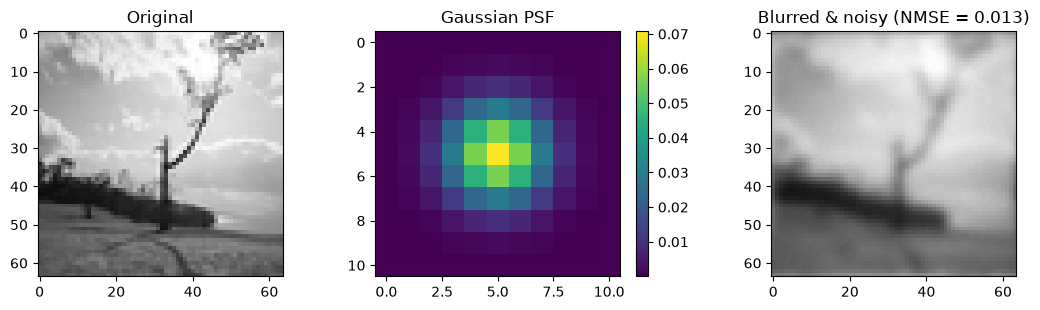

In [45]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
im = ax[1].imshow(problem.psf, cmap="viridis")
ax[1].set_title("Gaussian PSF")
ax[2].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Blurred & noisy (NMSE = {:.3f})".format(nmse_b))
fig.colorbar(im, ax=ax[1])
plt.tight_layout()

## O tamanho do problema

Aqui surge rapidamente uma dificuldade importante. Uma imagem de apenas $64\times64$ pixels possui um total de $64^2 = 4096$ pixels (ou incógnitas - do ponto de vista do problema inverso). Se representarmos explicitamente o operador de convolução por uma matriz cheia, teremos

\begin{equation}
\mathbf{A}\in
\mathbb{R}^{4096 \times 4096},
\end{equation}

ou aproximadamente $16.8 \times 10^6$ elementos. Armazenando cada elemento como um ``float64`` (64 bits ou 8 bytes), essa matriz ocuparia aproximadamente 0,125 GB.

Para uma imagem $256\times256$, teríamos $65536$ pixels (ou incógnitas) e uma matriz $\mathbf{A}\in
\mathbb{R}^{65536\times65536}$ com mais de $4.29 \times 10^9$ elementos — aproximadamente 34 GB apenas para armazenar $\mathbf{A}$.

Esse crescimento ilustra imediatamente a motivação apresentada anteriormente: embora o problema possa ser escrito formalmente como $\mathbf{A}\mathbf{x}=\mathbf{b}$, formar e fatorar explicitamente $\mathbf{A}$ rapidamente deixa de ser uma estratégia viável.

Isto não deve nos impedir de tentar com métodos tradicionais, desde que as dimensões do problema se restrinjam a valores viáveis.

# Tikhonov deblurring

Vamos tentar fazer o deblurring usando o método de Tikhonov (`pyregtools.regsolvers.tikhonov`) com seleção automática do parâmetro de regularização via GCV (Generalized Cross Validation - `pyregtools.regchoice.gcv_lambda`). Os passos são:

- Computar o SVD de $\mathbf{A}$
- Encontrar o parâmetro ótimo de regularização via GCV
- Resolver o problema inverso com o solver ``tikhonov``
- Plotar e analisar a imagem estimada.
  

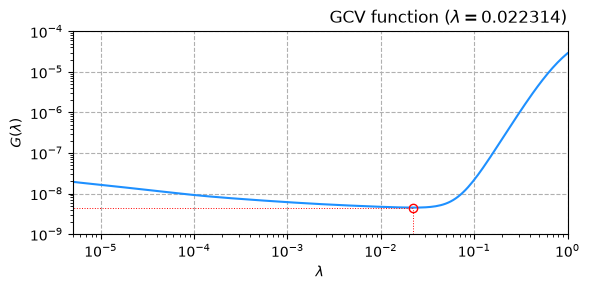

In [4]:
u, s, v = csvd(problem.A)
lam_opt = gcv_lambda(u, s, problem.b_noisy.ravel(order="C"), plot_gcvfun = True, r_min=0.000005)
x_est = tikhonov(u, s, v, problem.b_noisy.ravel(order="C"), lam_opt)
x_est = np.reshape(x_est, problem.shape, order="C")
nmse = nmse_fun(x_meas = x_est, x_ref = problem.b_true)

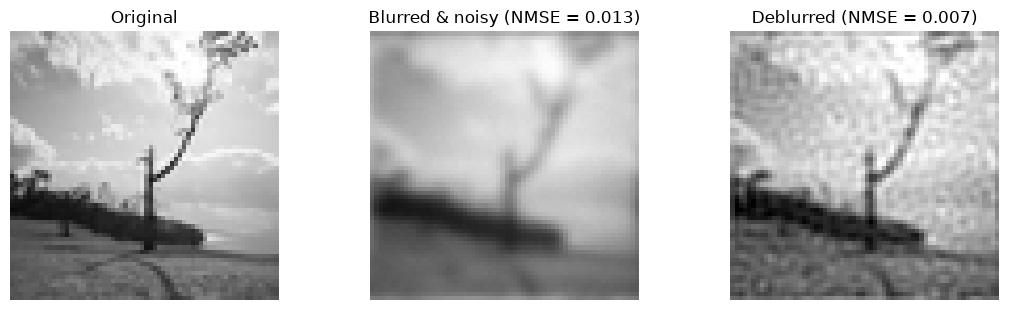

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Blurred & noisy (NMSE = {:.3f})".format(nmse_b))
ax[2].imshow(x_est, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Deblurred (NMSE = {:.3f})".format(nmse))
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### Pergunta: O que você notou? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- levou um bocado de tempo para computar tudo;
- o NMSE da solução é consideravelmente menor, mas
- a solução não é perfeita e possui ainda alguns efeitos do ruído.
</details> 

## Calculando o problema direto sem construir a matriz

Embora o problema direto possa ser escrito na forma $\mathbf{b}=\mathbf{A}\mathbf{x}$, não é necessário construir explicitamente a matriz $\mathbf{A}$ para calcular a imagem borrada. Podemos explorar propriedades da operação de convolução para realizar esse cálculo de forma muito mais eficiente.

#### Convolução separável

No problema considerado aqui, a PSF gaussiana é **separável**, isto é, $A(x, y) = A(x)A(y)$. Isto implica que a convolução bidimensional pode ser decomposta em duas convoluções unidimensionais: uma ao longo das linhas e outra ao longo das colunas. Se este for o caso, podemos realizar a convolução bidimensional com 

\begin{equation}
\mathbf{b} = \mathbf{A}_y \mathbf{x}_{\text{true}} \mathbf{A}_x^T,
\tag{5}
\end{equation}
em que $\mathbf{A}_y \in \mathbb{R}^{M \times M}$ e $\mathbf{A}_y \in \mathbb{R}^{L \times L}$. Essa estratégia é utilizada pelo método `blur_separable` do `ImageDeblur` e reduz significativamente tanto o custo computacional quanto a quantidade de memória necessária para resolver o problema direto.

In [46]:
problem.blur_separable()
problem.add_noise(snr=45, seed=42)
b_noisy_sep = np.copy(problem.b_noisy)
err_norm_sep = np.linalg.norm(b_noisy_sep-b_noisy_mtx)

print("Matrix shape is {} ({} GB)".format(problem.A.shape, memo))
print(r"Matrix A_y shape is {}".format(problem.A_y.shape))
print(r"Matrix A_x shape is {}".format(problem.A_x.shape))

Matrix shape is (4096, 4096) (0.125 GB)
Matrix A_y shape is (64, 64)
Matrix A_x shape is (64, 64)


#### Convolução utilizando a FFT

Outra possibilidade é calcular a convolução no domínio da frequência. Pelo **teorema da convolução**, uma convolução no domínio espacial (da imagem) corresponde a uma multiplicação no domínio da frequência espacial. Assim,

\begin{equation}
\mathcal{F}\mathcal{F}\{\mathbf{H} * \mathbf{X}\} = \mathcal{F}\mathcal{F}\{\mathbf{H}\} \mathcal{F}\mathcal{F}\{\mathbf{X}\},
\tag{6}
\end{equation}

em que $\mathcal{F}\mathcal{F}\{\cdot\}$ representa a transformada de Fourier bidimensional. Então, a imagem borrada pode ser calculada por meio de

\begin{equation}
\mathbf{B} =
\mathcal{F}^{-1}\mathcal{F}^{-1} \left\{\mathcal{F}\mathcal{F}\{\mathbf{H}\} \mathcal{F}\mathcal{F}\{\mathbf{X}_{\text{true}}\} \right\},
\tag{7}
\end{equation}
em que $\mathcal{F}\mathcal{F}\{\mathbf{X}_{\text{true}}\} \in \mathbb{C}^{M \times L}$ e $\mathcal{F}\mathcal{F}\{\mathbf{H}\} \in \mathbb{C}^{M \times L}$. 

Essa é a estratégia utilizada pelo método `blur_fft` do `ImageDeblur`. Para imagens maiores, o uso da FFT permite calcular a convolução de forma muito eficiente, sem a necessidade de construir a matriz $\mathbf{A}$.

As abordagens `blur_separable` e `blur_fft` produzem, portanto, a ação do operador do problema direto diretamente sobre a imagem, evitando o armazenamento explícito da grande matriz associada à convolução.

In [47]:
problem.blur_fft()
problem.add_noise(snr=45, seed=42)
b_noisy_fft = np.copy(problem.b_noisy)
err_norm_fft = np.linalg.norm(b_noisy_fft-b_noisy_mtx)
print("Matrix shape is {} ({} GB)".format(problem.A.shape, memo))
print(r"Matrix H_fft shape is {}".format(problem.H_fft.shape))
print(r"Matrix X_true shape is {}".format(problem.b_true.shape))

Matrix shape is (4096, 4096) (0.125 GB)
Matrix H_fft shape is (64, 64)
Matrix X_true shape is (64, 64)


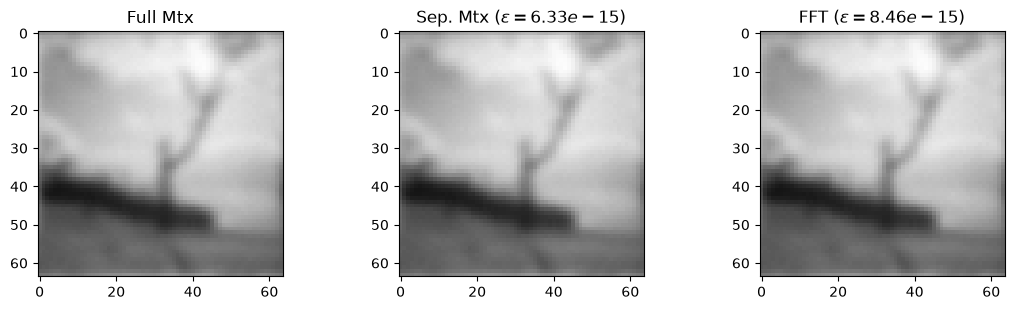

In [48]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(b_noisy_mtx, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Full Mtx")
ax[1].imshow(b_noisy_sep, cmap="gray", vmin=0, vmax=1)
ax[1].set_title(r"Sep. Mtx ($\epsilon = {:.2e}$)".format(err_norm_sep))
ax[2].imshow(b_noisy_fft, cmap="gray", vmin=0, vmax=1)
ax[2].set_title(r"FFT ($\epsilon = {:.2e}$)".format(err_norm_fft))
plt.tight_layout()

### Pergunta: O que você pode notar e se perguntar? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- A computação do problema direto via ``blur_seperable`` ou ``blur_fft`` é muito mais eficiente e reduz drasticamente as dimensões do problema direto;
- Será que conseguimos montar o problema inverso evitando montar a matriz $\mathbf{A}$?
- A resposta imediata é **sim**, mas os algoritmos vistos até aqui não foram escritos para problemas bidimensionais. Mas os solvers iterativos  podem fazê-lo.
</details> 

# Alguns métodos iterativos estacionários

Iniciamos o estudo dos métodos de **regularização iterativa** com uma breve discussão sobre alguns métodos iterativos estacionários clássicos que apresentam **semiconvergência**. Embora esses métodos não sejam adequados como métodos de regularização iterativa de propósito geral, pois podem apresentar convergência muito lenta, eles possuem aplicações específicas nas quais são competitivos com outros métodos, como em problemas de tomografia. Além disso, esses métodos permitem compreender alguns dos mecanismos fundamentais da regularização iterativa e estabelecer relações com os métodos de regularização estudados anteriormente.

## Método de Landweber

Um dos métodos iterativos mais conhecidos, que apresenta **semiconvergência**, é o método de Landweber. Ele pode ser interpretado como uma **descida do gradiente** (*gradient descent*) aplicada ao problema de mínimos quadrados

\begin{equation}
\min_{\mathbf{x}} J(\mathbf{x}),
\qquad
J(\mathbf{x}) = \frac{1}{2}\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2.
\end{equation}

O gradiente da função objetivo é

\begin{equation}
\nabla J(\mathbf{x}) = \mathbf{A}^H(\mathbf{A}\mathbf{x}-\mathbf{b}) = -\mathbf{A}^H\mathbf{r}.
\end{equation}

Portanto, o produto $\mathbf{A}^H\mathbf{r}$ indica uma direção na qual podemos ajustar a solução atual para reduzir o erro de mínimos
quadrados. O parâmetro $\omega$ determina o tamanho do passo nessa direção. Assim, a cada iteração, o método calcula o erro entre os dados medidos e os previstos pelo modelo, $\mathbf{r}=\mathbf{b}-\mathbf{A}\mathbf{x}$, e retropropaga esse erro por meio de $\mathbf{A}^H$ para corrigir a solução.

Uma iteração do método de descida do gradiente é
\begin{equation}
\mathbf{x}^{[k+1]} = \mathbf{x}^{[k]} -\omega\nabla J(\mathbf{x}^{[k]}).
\end{equation}
Substituindo o gradiente, a atualização da solução é dada por

\begin{equation}
\mathbf{x}^{[k+1]} = \mathbf{x}^{[k]} + \omega \overbrace{\mathbf{A}^{H}}^{\text{adjunta}} \underbrace{\left(\mathbf{b}-\mathbf{A}\mathbf{x}^{[k]}\right)}_{\text{resíduo}},
\tag{8}
\end{equation}
Para garantir a convergência, deve-se escolher 

\begin{equation}
0 < \omega < \frac{2}{\|\mathbf{A}^{H}\mathbf{A}\|_2} = \frac{2}{\sigma_1^2},
\tag{9}
\end{equation}
em que $\sigma_1$ é o maior valor singular de $\mathbf{A}$. Assim, cada iteração requer, essencialmente, o cálculo do resíduo, a aplicação de $\mathbf{A}^{H}$ e a atualização da solução. Não é necessário calcular a fatoração de $\mathbf{A}$ em SVD.

### A matriz adjunta vs. a matriz inversa

A operação $\mathbf{A}^{-1}\mathbf{b} = \mathbf{x}$, quando existe, procura desfazer a ação de $\mathbf{A}\mathbf{x}=\mathbf{b}$. A matriz $\mathbf{A}^{H}$ representa a matriz **adjunta** de $\mathbf{A}$ e tem outro papel: ela permite relacionar variações no espaço da solução com quantidades no espaço dos dados.

Considere uma pequena alteração $\delta\mathbf{x}$ na solução. A alteração correspondente nos dados é $\mathbf{A}\delta\mathbf{x}$. Para comparar essa
alteração com o resíduo $\mathbf{r}$, calculamos o produto interno, dado por 

\begin{equation}
\langle \mathbf{A}\delta\mathbf{x},\mathbf{r}\rangle.
\end{equation}

Pela definição da adjunta,

\begin{equation}
\langle \mathbf{A}\delta\mathbf{x},\mathbf{r}\rangle = \langle\delta\mathbf{x},\mathbf{A}^H\mathbf{r}\rangle.
\tag{10}
\end{equation}

Assim, $\mathbf{A}^H\mathbf{r}$ expressa, no espaço da solução, a informação contida no resíduo relevante para **alterar** $\mathbf{x}$. Ela não desfaz o problema direto, mas fornece uma **direção de correção**.

Vamos aplicar estes conceitos num problema de grande porte.

In [64]:
size = 400
problem = ImageDeblur(image_name="moon.png", shape=(size, size))
problem.gaussian_psf(sigma=2.5)
problem.blur_fft()
problem.add_noise(snr=45, seed=42)
nmse_b = nmse_fun(x_meas = problem.b_noisy, x_ref = problem.b_true)
memo = ((size**2)**2)*8/((1024**3))
print("Matrix shape is {} x {} ({:.2f} GB)".format(size**2, size**2, memo))

Matrix shape is 160000 x 160000 (190.73 GB)


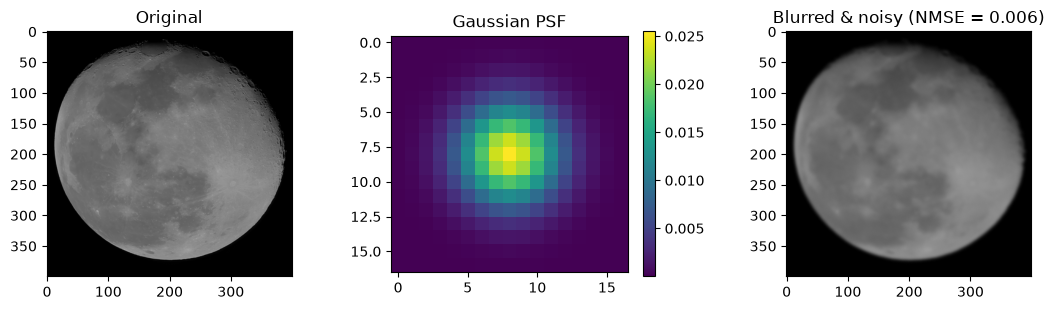

In [65]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
im = ax[1].imshow(problem.psf, cmap="viridis")
ax[1].set_title("Gaussian PSF")
ax[2].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Blurred & noisy (NMSE = {:.3f})".format(nmse_b))
fig.colorbar(im, ax=ax[1])
plt.tight_layout()

### Operando com $\mathbf{A}$ sem construir $\mathbf{A}$

A formulação matricial é muito útil para compreender o problema,

\begin{equation}
\mathbf{b} = \mathbf{A}\mathbf{x},
\end{equation}

mas isso não significa que precisamos construir e armazenar a matriz $\mathbf{A}$.

Para aplicar o método de Landweber, precisamos essencialmente de duas operações:

\begin{equation}
\mathbf{x} \longmapsto \mathbf{A}\mathbf{x}
\tag{11}
\end{equation}

e

\begin{equation}
\mathbf{y} \longmapsto \mathbf{A}^H\mathbf{y}.
\tag{12}
\end{equation}

No problema de *image deblurring*, essas duas operações podem ser calculadas diretamente por meio da FFT, sem que a matriz $\mathbf{A}$ seja construída.

### Operador direto e operador adjunto usando FFT

Se o borramento é descrito pela convolução da imagem com uma PSF, o problema direto pode ser calculado no domínio da frequência como

\begin{equation}
\widehat{\mathbf{B}} =
\mathcal{F}\mathcal{F}\{\mathbf{H}\} \ \mathcal{F}\mathcal{F}\{\mathbf{X}_{\text{true}}\} = \widehat{\mathbf{H}}\odot\widehat{\mathbf{X}},
\end{equation}
em que $\odot$ representa a multiplicação elemento a elemento.

Também podemos definir a operação adjunta. Considere uma imagem (ou o resíduo da imagem) $\mathbf{Y}$ pertencente ao espaço dos dados. A aplicação da adjunta produz uma imagem $\mathbf{Z}$ no espaço da solução:

\begin{equation}
\mathbf{Z} = \mathcal{F}\mathcal{F}^{-1}\left\{(\mathcal{F}\mathcal{F}\{\mathbf{H}\})^H \mathcal{F}\mathcal{F}\{\mathbf{Y}\}\right\} =\mathcal{F}\mathcal{F}^{-1}\left\{\overline{\widehat{\mathbf{H}}} \odot \widehat{\mathbf{Y}}\right\},
\end{equation}

em que $\overline{\widehat{\mathbf{H}}}$ representa o complexo conjugado da resposta da PSF no domínio da frequência e $\widehat{\mathbf{Y}}=\mathcal{F}\mathcal{F}\{\mathbf{Y}\}$.

Aqui, $\mathbf{Y}$ representa uma entrada genérica do operador adjunto. Assim como o operador direto transforma uma imagem do espaço da solução em uma
imagem no espaço dos dados, o operador adjunto realiza o mapeamento no sentido oposto, do espaço dos dados para o espaço da solução. É importante ressaltar que o operador adjunto não é o operador inverso: sua aplicação não desfaz necessariamente o borramento. O operador direto e sua
adjunta são definidos pelo problema e não dependem do método utilizado para resolver o problema inverso.

No método de Landweber, entretanto, a imagem de entrada do operador adjunto, $\mathbf{Y}$, é o resíduo entre a imagem observada e a imagem prevista pela solução atual,

\begin{equation}
\mathbf{Y} = \mathbf{R}^{[k]}= \mathbf{B}_{\mathrm{obs}}-\operatorname{blur}(\mathbf{X}^{[k]}).
\end{equation}

Assim, a operação direta transforma a estimativa atual $\mathbf{X}^{[k]}$ em uma imagem borrada, que pode ser comparada aos dados medidos. A operação adjunta recebe o erro dessa previsão, $\mathbf{R}^{[k]}$, e o transforma em uma imagem $\mathbf{Z}^{[k]}$, que indica como a estimativa atual deve ser corrigida.

Portanto, podemos implementar duas funções: uma que calcula o borramento e outra que calcula a operação adjunta. Nenhuma delas requer a construção da
matriz do sistema. O operador ``scipy.sparse.linalg.LinearOperator`` empacota tudo e executa as operações. Nos solvers iterativos do ``PyRegTools``, você pode passar a matriz $\mathbf{A}$ ou o objeto correspondente do tipo ``scipy.sparse.linalg.LinearOperator``.

In [66]:
def matvec(x):
    X = x.reshape(problem.shape)
    B = np.fft.ifft2(problem.H_fft * np.fft.fft2(X))
    return B.real.ravel()

H_fft_H = np.conj(problem.H_fft) # Implicit transposition as the operator is diagonal

def rmatvec(y):
    Y = y.reshape(problem.shape)
    X = np.fft.ifft2(H_fft_H * np.fft.fft2(Y))
    return X.real.ravel()

Aop = scipy.sparse.linalg.LinearOperator(shape=(problem.n_pixels, problem.n_pixels), matvec=matvec, rmatvec=rmatvec, dtype=float)

In [55]:
num_iterations = 600
x_est_h, sol_norms, res_norms = landweber(Aop, problem.b_noisy.ravel(order="C"), omega = 2, x0 = None, max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (65536, 600)


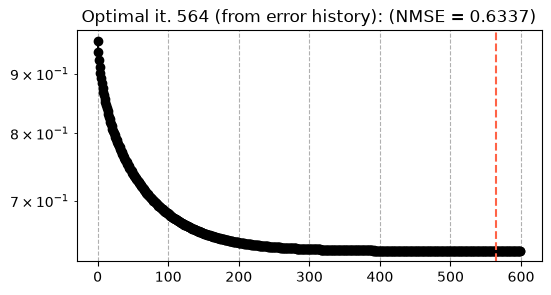

In [56]:
error_hist = nmse_fun(x_est_h, problem.b_true.ravel(order="C")[:, None], axis=0)
k_opt = np.argmin(error_hist)
plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, '-ok')
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.4f})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
#plt.ylim((0.003, 0.03))
plt.show()

In [57]:
x_est = np.reshape(x_est_h[:,k_opt], problem.shape, order="C")
nmse = nmse_fun(x_meas = x_est, x_ref = problem.b_true)

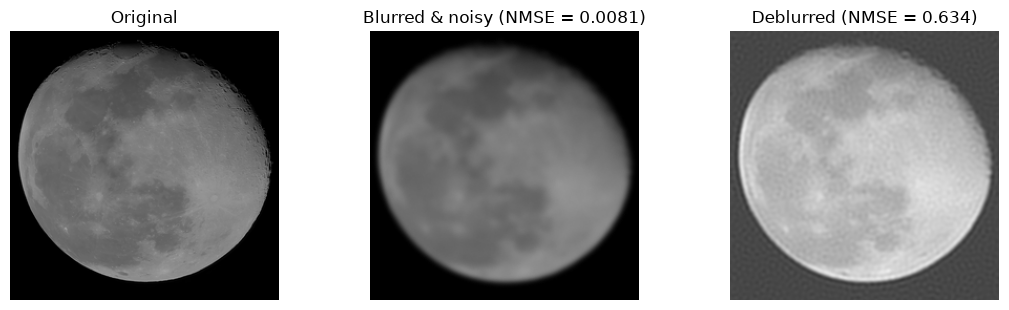

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Blurred & noisy (NMSE = {:.4f})".format(nmse_b))
ax[2].imshow(x_est, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Deblurred (NMSE = {:.3f})".format(nmse))
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### Pergunta: O que você nota? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- a convergência (ou semiconvergência) é lenta (muitas iterações foram necessárias);
- neste caso específico, a última iteração parece ter sido a com menor NMSE (assumindo que conhecemos o valor verdadeiro - o que na prática não será o caso);
- a imagem começa nula (chute inicial é um $\mathbf{x} = [0, 0, \ldots, 0]^T$) e vai vagarosamente tendendo à solução regularizada. Se muitas iterações são usadas, as partes escuras da imagem tendem a ficar mais claras;
- a escolha de $\omega$ tem um papel importante. Valores muito grandes levam à não-convergência. Com o uso do ``scipy.sparse.linalg.LinearOperator``, $\omega$ torna-se um hiperparâmetro difícil de estimar, pois você não tem mais acesso à matriz $\mathbf{A}$ e à sua norma (vide Eq. (9)).
</details> 

#### Por que a parada antecipada regulariza a solução?

As soluções produzidas pelo método de Landweber também podem ser interpretadas como **soluções SVD filtradas**, de maneira semelhante às obtidas por TSVD e pela regularização de Tikhonov.

Considerando, por simplicidade, $\mathbf{x}^{[0]}=\mathbf{0}$ e a decomposição

\begin{equation}
\mathbf{A}
=
\mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^H,
\end{equation}

a solução após $k$ iterações pode ser escrita como

\begin{equation}
\mathbf{x}^{[k]}
=
\mathbf{V}
\boldsymbol{\Phi}^{[k]}
\boldsymbol{\Sigma}^{-1}
\mathbf{U}^H\mathbf{b},
\end{equation}

em que

\begin{equation}
\boldsymbol{\Phi}^{[k]}
=
\operatorname{diag}
\left(
\phi_1^{[k]},\ldots,\phi_n^{[k]}
\right)
\end{equation}

contém os **fatores de filtro** do método de Landweber. Para cada valor singular
$\sigma_i$, o fator de filtro é

\begin{equation}
\phi_i^{[k]}
=
1-\left(1-\omega\sigma_i^2\right)^k.
\end{equation}

Para valores singulares pequenos, podemos usar a série de Taylor e, por conseguinte, a aproximação

\begin{equation}
\phi_i^{[k]}
\approx
k\omega\sigma_i^2.
\end{equation}

Portanto, nas primeiras iterações, as componentes associadas aos pequenos
valores singulares são fortemente atenuadas. Essas são justamente as
componentes que apresentam maior amplificação do ruído na solução não
regularizada.

À medida que $k$ aumenta, os fatores $\phi_i^{[k]}$ se aproximam de 1 e componentes associadas a valores singulares cada vez menores passam a fazer parte da solução. Inicialmente, isso melhora a reconstrução, mas, após certo ponto, também permite que componentes fortemente contaminados por ruído sejam amplificados.

Essa interpretação explica tanto o efeito de **regularização pela parada antecipada** quanto o fenômeno da **semiconvergência**: o número de iterações
$k$ atua como um parâmetro de regularização.

## Método de Landweber-Cimmino

Outro método iterativo clássico que apresenta semiconvergência é o método de Cimmino. Uma de suas formas pode ser escrita como

\begin{equation}
\mathbf{x}^{[k+1]} = \mathbf{x}^{[k]} + \omega\mathbf{A}^{H}\mathbf{D} \left(\mathbf{b}-\mathbf{A}\mathbf{x}^{[k]}\right),
\tag{13}
\end{equation}

em que $\mathbf{D}=\operatorname{diag}(d_i)$ é uma matriz diagonal cujos elementos dependem das linhas de $\mathbf{A}$.

Denotando a $i$-ésima linha de $\mathbf{A}$ por $\mathbf{a}_i^H$, temos

\begin{equation}
d_i =
\begin{cases}
\dfrac{1}{m\|\mathbf{a}_i\|_2^2},
& \mathbf{a}_i \neq \mathbf{0},\\[6pt]
0,
& \mathbf{a}_i = \mathbf{0},
\end{cases}
\tag{14}
\end{equation}

em que $M$ é o número de linhas de $\mathbf{A}$.

Comparado ao método de Landweber, o método de Cimmino introduz, portanto,
uma ponderação do resíduo por meio da matriz $\mathbf{D}$. Cada componente do
resíduo é ponderado de acordo com a norma da linha correspondente de
$\mathbf{A}$ antes da aplicação do operador adjunto.

A normalização introduzida por $\mathbf{D}$ também simplifica a escolha do
parâmetro de relaxação. Com a definição acima, pode-se utilizar

\begin{equation}
0 < \omega < 2/\left\|\mathbf{D}^{1/2}\mathbf{A}\right\|_2^2.
\tag{15}
\end{equation}

Assim como no método de Landweber, $\omega$ controla o tamanho da correção
realizada a cada iteração. Valores próximos do limite superior podem acelerar
a convergência, mas também podem produzir um comportamento menos suave.

# CGLS e os subespaços de Krylov

O método **CGLS** (*Conjugate Gradient for Least Squares*) é um método iterativo
para resolver o problema de mínimos quadrados

\begin{equation}
\min_{\mathbf{x}}
\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2.
\end{equation}

Uma forma de compreender o CGLS é por meio da ideia de **projeção em subespaços de Krylov**.

Em vez de procurar imediatamente uma solução em todo o espaço $\mathbb{C}^n$, o CGLS procura, a cada iteração, uma solução dentro de um
subespaço de dimensão relativamente pequena. Para $\mathbf{x}^{[0]}=\mathbf{0}$, esse subespaço é

\begin{equation}
\mathcal{K}_k
=
\mathcal{K}_k
\left(
\mathbf{A}^H\mathbf{A},
\mathbf{A}^H\mathbf{b}
\right)
=
\operatorname{span}
\left\{\underbrace{
\mathbf{A}^H\mathbf{b}}_{\mathcal{K}_1},
\underbrace{(\mathbf{A}^H\mathbf{A})\mathbf{A}^H\mathbf{b}}_{\mathcal{K}_2},
\ldots,
\underbrace{(\mathbf{A}^H\mathbf{A})^{k-1}\mathbf{A}^H\mathbf{b}}_{\mathcal{K}_k}
\right\}.
\tag{16}
\end{equation}

Isso já deve parecer familiar: $\mathbf{A^H}\mathbf{b}$ aponta na direção do **gradiente** quando começamos em zero. Depois acrescentamos espaços mais completos ($\mathcal{K}_2, \ldots, \mathcal{K}_k$).

#### Intuição: resolver um problema menor

Considere uma matriz $\mathbf{V}_k$ cujas colunas formam uma base para o
subespaço $\mathcal{K}_k$. Qualquer solução pertencente a esse espaço pode
ser escrita como

\begin{equation}
\mathbf{x}=\mathbf{V}_k\mathbf{y},
\end{equation}

em que $\mathbf{y}\in\mathbb{C}^k$ contém as coordenadas da solução nessa base.

O problema de mínimos quadrados fica então restrito a

\begin{equation}
\min_{\mathbf{y}}
\|\mathbf{A}\mathbf{V}_k\mathbf{y}-\mathbf{b}\|_2.
\end{equation}

Assim, nas primeiras iterações, o algoritmo não possui liberdade para buscar
qualquer solução possível: ele procura a melhor solução dentro de um espaço
de dimensão reduzida. À medida que $k$ aumenta, novos vetores são incorporados ao espaço de busca
e a solução pode representar progressivamente mais componentes do problema. Portanto, o espaço de busca cresce progressivamente,

\begin{equation}
\mathcal{K}_1
\subset
\mathcal{K}_2
\subset
\mathcal{K}_3
\subset
\cdots,
\end{equation}

permitindo que soluções cada vez mais complexas sejam representadas.

## O algoritmo CGLS

O problema de mínimos quadrados

\begin{equation}
\min_{\mathbf{x}}
\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2
\end{equation}

está associado às **equações normais**

\begin{equation}
\mathbf{A}^H\mathbf{A}\mathbf{x}
=
\mathbf{A}^H\mathbf{b}.
\tag{17}
\end{equation}

Como $\mathbf{A}^H\mathbf{A}$ é positiva semidefinida, podemos
aplicar as ideias do método dos gradientes conjugados a esse sistema. O método
resultante é conhecido como **CGLS — Conjugate Gradient for Least Squares**.

É importante, entretanto, que o CGLS não requeira a construção explícita da
matriz $\mathbf{A}^H\mathbf{A}$. O algoritmo utiliza apenas aplicações
sucessivas do operador direto e de sua adjunta.

Considere uma estimativa inicial $\mathbf{x}^{[0]}$. Definimos inicialmente o resíduo no espaço dos dados,

\begin{equation}
\mathbf{r}^{[0]}
=
\mathbf{b}-\mathbf{A}\mathbf{x}^{[0]},
\end{equation}

e aplicamos a adjunta a esse resíduo,

\begin{equation}
\mathbf{s}^{[0]}
=
\mathbf{A}^H\mathbf{r}^{[0]}.
\end{equation}

O vetor $\mathbf{s}^{[0]}$ está no espaço da solução e corresponde ao negativo
do gradiente da função de mínimos quadrados. A primeira direção de busca é

\begin{equation}
\mathbf{p}^{[0]}=\mathbf{s}^{[0]}.
\end{equation}

Em cada iteração, calculamos inicialmente como a direção de busca
$\mathbf{p}^{[k]}$ aparece no espaço dos dados,

\begin{equation}
\mathbf{q}^{[k]}
=
\mathbf{A}\mathbf{p}^{[k]}.
\end{equation}

O tamanho do passo ao longo dessa direção é dado por

\begin{equation}
\alpha_k
=
\frac{
\|\mathbf{s}^{[k]}\|_2^2
}{
\|\mathbf{q}^{[k]}\|_2^2
}.
\end{equation}

A solução e o resíduo são então atualizados por

\begin{equation}
\mathbf{x}^{[k+1]}
=
\mathbf{x}^{[k]}
+
\alpha_k\mathbf{p}^{[k]},
\end{equation}

\begin{equation}
\mathbf{r}^{[k+1]}
=
\mathbf{r}^{[k]}
-
\alpha_k\mathbf{q}^{[k]}.
\end{equation}

Aplicamos novamente a adjunta ao novo resíduo,

\begin{equation}
\mathbf{s}^{[k+1]}
=
\mathbf{A}^H\mathbf{r}^{[k+1]}.
\end{equation}

A nova direção de busca não é simplesmente $\mathbf{s}^{[k+1]}$. Ela combina
o novo gradiente com a direção utilizada anteriormente:

\begin{equation}
\beta_k
=
\frac{
\|\mathbf{s}^{[k+1]}\|_2^2
}{
\|\mathbf{s}^{[k]}\|_2^2
},
\end{equation}

\begin{equation}
\mathbf{p}^{[k+1]}
=
\mathbf{s}^{[k+1]}
+
\beta_k\mathbf{p}^{[k]}.
\end{equation}

Essa escolha produz direções conjugadas com relação a
$\mathbf{A}^H\mathbf{A}$, isto é,

\begin{equation}
(\mathbf{p}^{[i]})^H
\mathbf{A}^H\mathbf{A}
\mathbf{p}^{[j]}
=
0,
\qquad i\neq j,
\end{equation}
ou seja, as direções são escolhidas de forma que, quando vistas no espaço dos dados, sejam ortogonais. O CGLS não fica simplesmente dando novos passos de gradiente que podem parcialmente desfazer o progresso anterior.

As recorrências acima são uma maneira eficiente de construir a solução no
subespaço de Krylov sem formar explicitamente sua base. Após $k$ iterações,

\begin{equation}
\mathbf{x}^{[k]}
\in
\mathcal{K}_k
\left(
\mathbf{A}^H\mathbf{A},
\mathbf{A}^H\mathbf{b}
\right),
\end{equation}

para $\mathbf{x}^{[0]}=\mathbf{0}$.

Além disso, o CGLS escolhe, nesse espaço, a solução que minimiza o resíduo. Assim, cada iteração expande o espaço de soluções disponíveis e
resolve o problema de mínimos quadrados da melhor forma possível nesse novo espaço. Isto produz um método que tende a uma **semiconvergência** muito mais rápida que o método de Landweber.

Além disso, uma iteração de CGLS não possui hiperparâmetros de entrada e requer, essencialmente, uma aplicação do problema direto e uma aplicação da adjunta. Portanto, podemos usar exatamente as operações FFT que já construímos e nunca formar $\mathbf A$ nem $\mathbf A^H\mathbf A$.

In [67]:
num_iterations = 100
x_est_h, sol_norms, res_norms = cgls(Aop, problem.b_noisy.ravel(order="C"), max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (160000, 100)


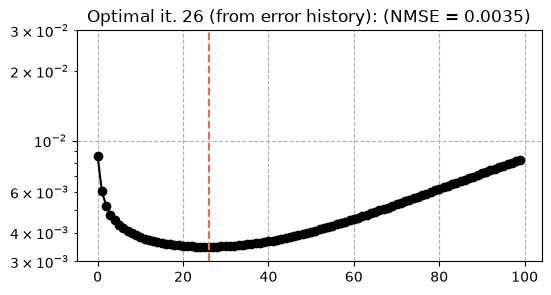

In [68]:
error_hist = nmse_fun(x_est_h, problem.b_true.ravel(order="C")[:, None], axis=0)
k_opt = np.argmin(error_hist)

plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, '-ok')
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.4f})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
plt.ylim((0.003, 0.03))
plt.show()

# Escolha do número de iterações pela curva L

Nos métodos de regularização iterativa, o número de iterações $k$ desempenha o papel de parâmetro de regularização. Uma possibilidade para selecionar esse parâmetro é utilizar a **curva L**, construída a partir das normas do resíduo e da solução em cada iteração:

\begin{equation}
\rho_k = \|\mathbf{A}\mathbf{x}^{[k]}-\mathbf{b}\|_2,
\qquad
\eta_k = \|\mathbf{x}^{[k]}\|_2.
\end{equation}

A curva é representada em escala logarítmica, com $\rho_k$ no eixo horizontal e $\eta_k$ no vertical. Quando apresenta o formato característico de um L, sua quina representa uma região de compromisso entre o ajuste aos dados e a magnitude da solução.

Para localizar automaticamente essa quina, utilizamos a função `regchoice.lcurve_discrete` do `PyRegTools`, baseada no **método dos triângulos** de Castellanos et al. (2002).

O algoritmo realiza três etapas principais:

1. **Filtragem:** remove pontos que não seguem o comportamento esperado da curva L, isto é, a diminuição da norma do resíduo acompanhada pelo aumento da norma da solução.
2. **Normalização:** transforma as normas em coordenadas logarítmicas e reescala cada eixo para o intervalo $[-10,10]$.
3. **Identificação do canto:** constrói triângulos entre pontos da curva e utiliza suas propriedades geométricas, especialmente a orientação e os ângulos internos, para identificar o ponto associado ao canto.

A função retorna o índice da solução selecionada na sequência original de iterações. Assim, podemos obter diretamente a solução regularizada correspondente.

É importante observar que **nem todos** os métodos iterativos produzem uma curva em formato de L bem definida. Quando isso não ocorre, a identificação automática da quina pode não fornecer um critério confiável para interromper as iterações.


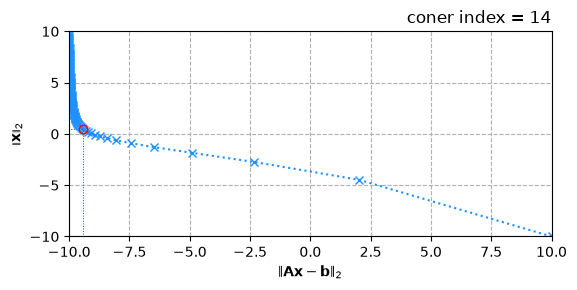

In [69]:
k_l = lcurve_discrete(res_norms, sol_norms, plotit=True)
x_est = np.reshape(x_est_h[:,k_l], problem.shape, order="C")
nmse = nmse_fun(x_meas = x_est, x_ref = problem.b_true)

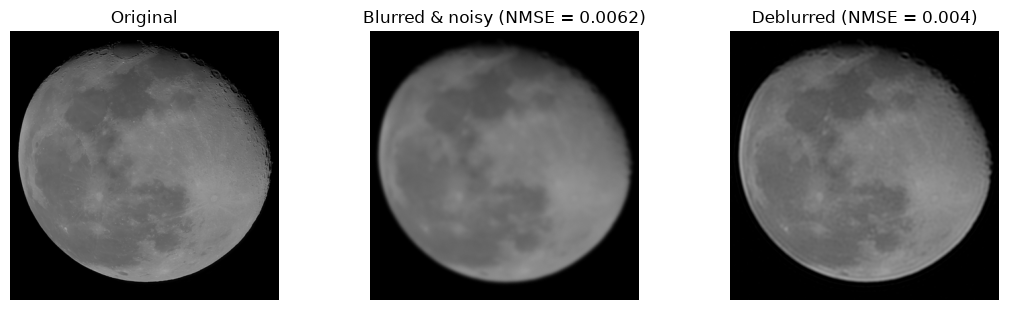

In [70]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].imshow(problem.b_true, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Original")
ax[1].imshow(problem.b_noisy, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Blurred & noisy (NMSE = {:.4f})".format(nmse_b))
ax[2].imshow(x_est, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Deblurred (NMSE = {:.3f})".format(nmse))
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

# Algebraic Reconstruction Technique (ART)

O método **ART** (*Algebraic Reconstruction Technique*), também conhecido como **método de Kaczmarz**, é um método iterativo estacionário, que utiliza **uma equação do sistema linear por vez** para atualizar a solução.

Considere o sistema

\begin{equation}
\mathbf{A}\mathbf{x}\simeq\mathbf{b}.
\end{equation}

Podemos escrever sua $i$-ésima equação como

\begin{equation}
\mathbf{a}_i^H\mathbf{x}=b_i,
\tag{18}
\end{equation}

em que $\mathbf{a}_i^H$ representa a $i$-ésima linha de $\mathbf{A}$.

Dada uma estimativa atual $\mathbf{x}$, o ART realiza a atualização

\begin{equation}
\mathbf{x}_{k+1}=
\mathbf{x}_k
+
\omega
\frac{b_i-\mathbf{a}_i^H\mathbf{x}_k}
{\|\mathbf{a}_i\|_2^2}
\mathbf{a}_i
\tag{19}
\end{equation}

em que $\omega$ é um parâmetro de relaxação. Para $0<\omega<2$, a atualização corresponde a uma projeção relaxada; quando $\omega=1$, obtemos a projeção ortogonal (usada no `PyRegTools`).

O algoritmo percorre sequencialmente as equações do sistema, corrigindo a solução para satisfazer cada uma delas.

Uma passagem completa por todas as $M$ equações é denominada **varredura** (*sweep*). Na implementação utilizada no ``PyRegTools``, uma iteração corresponde a uma varredura completa.

### ART e regularização iterativa

Em problemas inversos com dados ruidosos, o sistema de equações pode ser inconsistente: não existe uma solução que satisfaça exatamente todas as equações simultaneamente. Assim como nos métodos anteriores, o ART pode apresentar **semiconvergência**. Nas primeiras iterações, a solução pode se aproximar da solução exata, enquanto iterações adicionais podem aumentar a influência do ruído e deteriorá-la. Nesse contexto, o número de iterações funciona como um parâmetro de regularização, e a interrupção antecipada do algoritmo pode produzir soluções mais estáveis.

### Aspectos computacionais

Uma característica importante do ART é que ele não precisa acessar a matriz $\mathbf{A}$ inteira a cada atualização. Basta conhecer a linha correspondente à equação em processamento. Isso torna o método particularmente interessante para problemas em que as linhas de $\mathbf{A}$ podem ser geradas individualmente, como na **tomografia computadorizada**, em que cada linha representa a contribuição de um pixel para uma determinada medida de projeção.

Por outro lado, como as atualizações são realizadas sequencialmente, o ART pode exigir muitas operações para concluir uma varredura de problemas com um grande número de medidas. Sua eficiência depende, portanto, da estrutura da matriz e do custo de acesso a cada linha.

Por questões de custo computacional, vamos avaliar o ART para o problema da gravidade.

In [71]:
problem = Gravity1D(lb = 0, ub = 1, d = 0.5) # instantiate
problem.sample_rho_mp(L = 64) # sample source field
problem.sample_g(M = 64) # sample measurement of g
problem.sens_mtx() # build the sensing matrix
problem.multi_density_sin(amplitude = [1.0, 0.5], kx = [np.pi, 2*np.pi]) # create a source term
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = 30, seed = 42) # add some noise

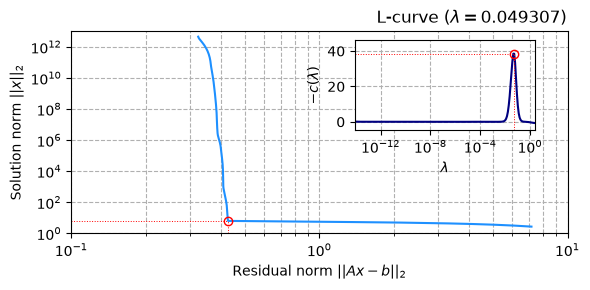

In [72]:
u, s, v = csvd(problem.A)
lam_opt = l_curve(u, s, problem.b_noisy, plotit = True)
x_est_l = tikhonov(u, s, v, problem.b_noisy, lam_opt)
nmse_l = nmse_fun(x_meas = x_est_l, x_ref = problem.x_true)

In [73]:
num_iterations = 100
x_est_h, sol_norms, res_norms = art_solver(problem.b_noisy, A=problem.A, get_row = None, 
                                           n_unknowns = None, x0=None, max_it = num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (64, 100)


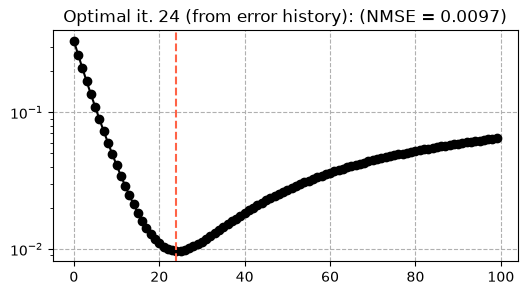

In [74]:
error_hist = nmse_fun(x_est_h, problem.x_true[:, None], axis=0)
k_opt = np.argmin(error_hist)

plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, '-ok')
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.4f})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
#plt.ylim((0.003, 0.03))
plt.show()

In [75]:
x_est_art = x_est_h[:,k_opt]
nmse_art = nmse_fun(x_meas = x_est_art, x_ref = problem.x_true)

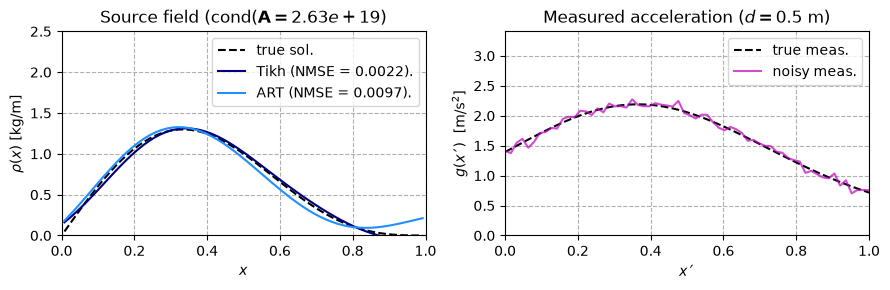

In [76]:
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(problem.x, problem.x_true, '--k', label = r'true sol.')
axs[0].plot(problem.x, x_est_l, color = 'navy', label = r'Tikh (NMSE = {:.4f}).'.format(nmse_l))
axs[0].plot(problem.x, x_est_art, color = 'dodgerblue', label = r'ART (NMSE = {:.4f}).'.format(nmse_art))
axs[0].legend(loc = 'upper right')
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((0, 2.5))
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (cond($\mathbf{{A}} = {:.2e}$)'.format(np.linalg.cond(problem.A)))
axs[1].plot(problem.coord, problem.b_true, '--k', label = r'true meas.')
axs[1].plot(problem.coord, problem.b_noisy, label = r'noisy meas.', 
            color = 'm', alpha = 0.7)
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((0, 1.5*np.amax(problem.b_noisy)))
axs[1].legend(loc = 'upper right')
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
axs[1].set_title(r'Measured acceleration ($d = {}$ m)'.format(problem.d))
plt.tight_layout()